In [8]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 1 — Imports and global config ###
# ════════════════════════════════════════════════════════════════════════════

import sys, os
sys.path.insert(0, "src")   # make src/ importable

import gc
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["figure.dpi"] = 120

# All seeds set here — mandatory for reproducibility
np.random.seed(42)
TEAM_NUMBER = "N"   # ← CHANGE THIS before submission

# Global parameters (set once in Part 1, reused everywhere)
K            = None   # filled after Part 1(a)
Q_THRESH     = None   # filled after Part 2(b)
T2_THRESH    = None   # filled after Part 2(b)
CLF_THRESH   = None   # filled after Part 3 calibration
TRAIN_MEAN   = None   # filled after Part 1(a)
EIGVECS_K    = None   # filled after Part 1(a)
EIGVALS_K    = None   # filled after Part 1(a)
MON_EV_RAT   = None   # filled after Part 1(a)
MON_EV2      = None   # filled after Part 1(a)



/Users/apple/Desktop/JPMC_QMP_Case-study_group6/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/apple/Desktop/JPMC_QMP_Case-study_group6/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/apple/Desktop/JPMC_QMP_Case-study_group6/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X


Component-count verdicts: {'kaiser': 3, 'broken_stick': 3, 'parallel': 3}


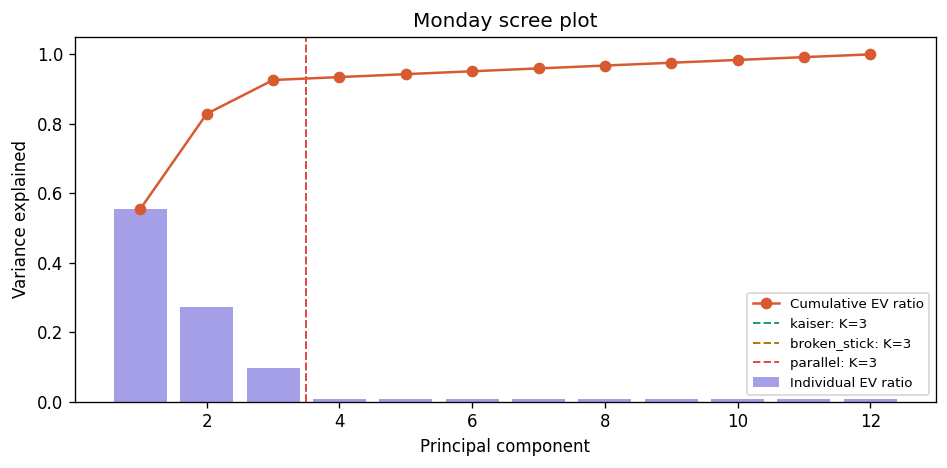


Chosen K = 3


In [9]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 2 — Part 1(a): Load Monday ticks, fit PCA, choose K ###
# ════════════════════════════════════════════════════════════════════════════

from p1_blind_cartographer import (
    load_and_pivot, fit_pca_on_monday,
    select_n_components, plot_scree
)

returns_mon = load_and_pivot("ticks_mon.csv")
pca_mon     = fit_pca_on_monday(returns_mon)

verdicts = select_n_components(
    pca_mon.explained_variance_,
    returns_mon.values,
    n_resamples=500, seed=42
)
print("Component-count verdicts:", verdicts)
plot_scree(pca_mon.explained_variance_, verdicts, title="Monday scree plot")

# ── Choose K ──
# If all three criteria agree: use that value.
# If they disagree: use Kaiser as the primary criterion and justify in markdown.
K = verdicts["kaiser"]
print(f"\nChosen K = {K}")

# Store references used by all downstream parts
TRAIN_MEAN  = returns_mon.values.mean(axis=0)
EIGVECS_K   = np.ascontiguousarray(pca_mon.components_[:K])
EIGVALS_K   = pca_mon.explained_variance_[:K]
MON_EV_RAT  = pca_mon.explained_variance_ratio_[:2]
MON_EV2     = np.ascontiguousarray(pca_mon.components_[:2])


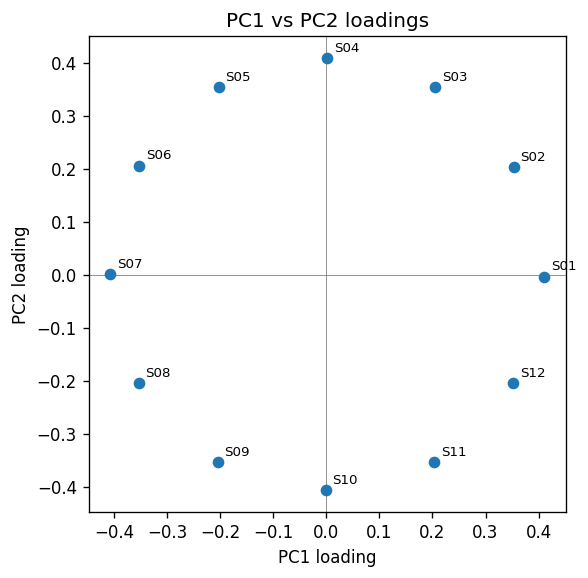

Original  — var(PC1)=0.000006  var(PC2)=0.000003  sum=0.000009
Rotated   — var(ax1)=0.000005  var(ax2)=0.000004  sum=0.000009
Joint variance is invariant under rotation ✓


/Users/apple/Desktop/JPMC_QMP_Case-study_group6/src/p1_blind_cartographer.py:185: RuntimeWarning: divide by zero encountered in matmul
  scores_orig = centred @ loadings_orig   # (T, 2)
/Users/apple/Desktop/JPMC_QMP_Case-study_group6/src/p1_blind_cartographer.py:185: RuntimeWarning: overflow encountered in matmul
  scores_orig = centred @ loadings_orig   # (T, 2)
/Users/apple/Desktop/JPMC_QMP_Case-study_group6/src/p1_blind_cartographer.py:185: RuntimeWarning: invalid value encountered in matmul
  scores_orig = centred @ loadings_orig   # (T, 2)
/Users/apple/Desktop/JPMC_QMP_Case-study_group6/src/p1_blind_cartographer.py:186: RuntimeWarning: divide by zero encountered in matmul
  scores_rot  = centred @ loadings_rot
/Users/apple/Desktop/JPMC_QMP_Case-study_group6/src/p1_blind_cartographer.py:186: RuntimeWarning: overflow encountered in matmul
  scores_rot  = centred @ loadings_rot
/Users/apple/Desktop/JPMC_QMP_Case-study_group6/src/p1_blind_cartographer.py:186: RuntimeWarning: invalid v

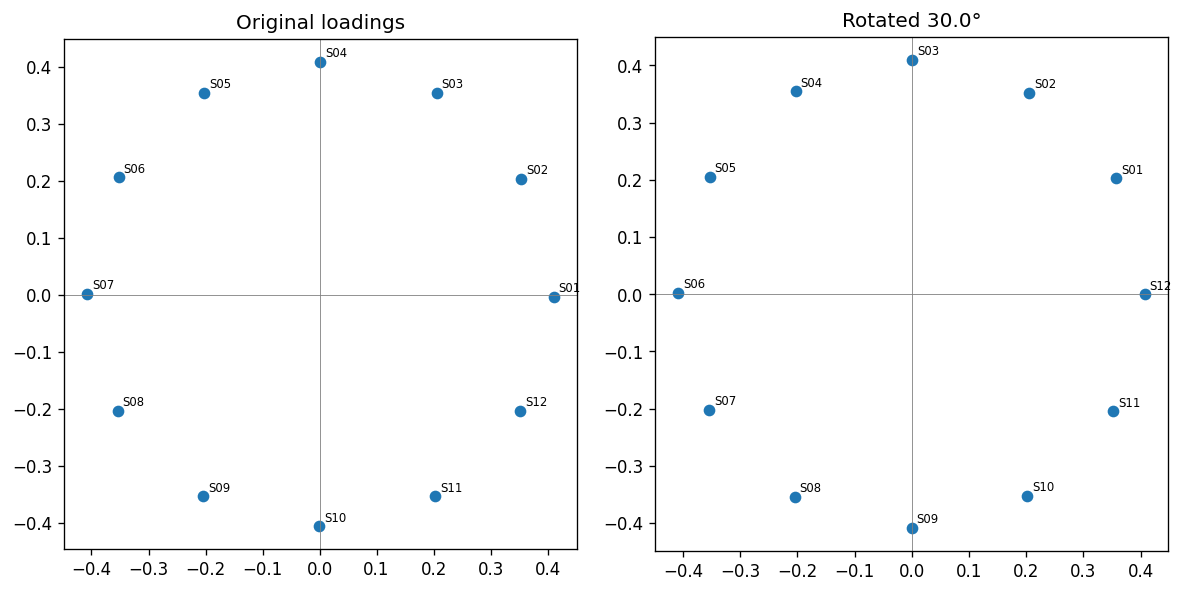

In [10]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 3 — Part 1(b): Loadings scatter and rotation ambiguity ###
# ════════════════════════════════════════════════════════════════════════════

from p1_blind_cartographer import (
    plot_loadings_scatter, demonstrate_rotation_ambiguity
)

asset_ids = list(returns_mon.columns)
loadings  = plot_loadings_scatter(pca_mon, asset_ids)
demonstrate_rotation_ambiguity(pca_mon, returns_mon.values, angle_deg=30.0)

# ── Markdown cell (write below this code cell in the notebook) ──
# Describe the polygon geometry.
# Explain rotation ambiguity: joint variance (λ1 + λ2) is invariant;
# per-axis decomposition changes; "PC1" and "PC2" labels are not unique.


In [11]:

# ════════════════════════════════════════════════════════════════════════════
### CELL 4 — Part 1(c): Information leakage quantification ###
# ════════════════════════════════════════════════════════════════════════════

from p1_blind_cartographer import quantify_leakage

returns_tue = load_and_pivot("ticks_tue.csv",
                              reference_columns=returns_mon.columns)

leakage = quantify_leakage(returns_mon, returns_tue, K)

# ── Markdown cell ──
# When is the gap largest? When Monday and Tuesday have different factor
# structures (regime change between days). Gap is smallest when they share
# the same structure (Monday conditions persist).
# Consequence: leaky procedure understates residual variance on Tuesday,
# making the desk's unhedged risk look smaller than it is.


ev_test_clean  = 0.867043
ev_test_leaky  = 0.867079
Leakage gap    = 0.000036


/Users/apple/Desktop/JPMC_QMP_Case-study_group6/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/apple/Desktop/JPMC_QMP_Case-study_group6/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/apple/Desktop/JPMC_QMP_Case-study_group6/.venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/apple/Desktop/JPMC_QMP_Case-study_group6/src/p1_blind_cartographer.py:237: RuntimeWarning: divide by zero encountered in matmul
  X_hat = X_c @ P.T @ P                  # projection back to n-dim space
/Users/apple/Desktop/JPMC_QMP_Case-study_group6/src/p1_blind_cartographer.py:237: RuntimeWarning: overflow encountered in matmul
  X_hat = X_c @ P.T @ P                  # projection back to n-dim space
/Users/apple/Desktop/JPMC_QMP_Case-study_gr

In [12]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 5 — Part 1(d): Neutrality proof ###
# ════════════════════════════════════════════════════════════════════════════

from p1_blind_cartographer import verify_neutrality

verify_neutrality(pca_mon, n_assets=12)

# ── Markdown cell — algebraic proof ──
# Under the 12-gon population assumption, the 12 asset loadings in the
# (PC1, PC2) plane sit at positions (cos(2πk/12), sin(2πk/12)) for k=0…11.
# Equal-weight portfolio loading on PC1:
#   w^T v1 = (1/12) Σ_{k=0}^{11} cos(2πk/12)
#           = Re[(1/12) Σ_{k=0}^{11} e^{i2πk/12}]
#           = Re[0] = 0
# (because the sum of all 12th roots of unity is zero)
# Similarly for PC2 via the imaginary part.
# QED.


Equal-weight loading on PC1: 2.820e-04  (expected ≈ 0)
Equal-weight loading on PC2: 3.234e-04  (expected ≈ 0)


(0.00028202810645190386, 0.000323367144664664)

In [13]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 6 — Part 1(e): Observations markdown cell ###
# ════════════════════════════════════════════════════════════════════════════

# Write 3–5 observations in a markdown cell. Required connection between (c) and (d):
# The neutrality proof relies on the 12-gon polygon geometry of the loadings.
# Leakage in (c) corrupts the eigenvectors used in the proof:
# when Tuesday's data is included in the PCA fit, the loadings cloud shifts
# away from the perfect 12-gon, making the equal-weight loading on PC1/PC2
# non-zero. The "no labels" argument fails because the loadings themselves
# carry information about the test-period structure.

In [ ]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 7 — Part 2(a–e): The Sentinel ###
# ════════════════════════════════════════════════════════════════════════════

from p2_sentinel_detector import run_sentinel

detector, thresh = run_sentinel(returns_mon, returns_tue, pca_mon, K)

Q_THRESH  = thresh["q_emp"]
T2_THRESH = thresh["t2_emp"]

print(f"\nQ_THRESH  = {Q_THRESH:.6f}")
print(f"T2_THRESH = {T2_THRESH:.6f}")

# ── Markdown cell: Production recommendation ──
# Recommended: Static PCA (Q) with Jackson-Mudholkar parametric threshold.
# Rationale: fires on out-of-model variation (structural breaks); zero-latency
# per-tick via precomputed projector; contribution decomposition immediately
# identifies the responsible asset; no random seed; fully interpretable.
# Streaming PCA adapts to drift but can absorb prolonged anomalies.
# Isolation Forest and MCD both lack contribution decomposition.


ValueError: time data "2026-06-01 09:00:00.840000+00:00" doesn't match format "%Y-%m-%d %H:%M:%S%z", at position 1. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [ ]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 8 — Part 3(a–d): The Regime Hunt + Thursday submission ###
# ════════════════════════════════════════════════════════════════════════════

from p3_regime_classifier import (
    build_streaming_features, calibrate_thresholds,
    RegimeClassifier, evaluate_on_wednesday, build_submission_csv
)

returns_wed = load_and_pivot("ticks_wed.csv",
                              reference_columns=returns_mon.columns)
returns_thu = load_and_pivot("ticks_thu.csv",
                              reference_columns=returns_mon.columns)

# Build features (strictly causal — no look-ahead)
WINDOW = 100
features_wed = build_streaming_features(
    returns_wed, window=WINDOW,
    monday_eigvecs_k=EIGVECS_K,
    monday_eigvecs_2=MON_EV2,
    train_mean=TRAIN_MEAN,
    monday_ev_ratios=MON_EV_RAT,
    q_threshold=Q_THRESH
)
features_thu = build_streaming_features(
    returns_thu, window=WINDOW,
    monday_eigvecs_k=EIGVECS_K,
    monday_eigvecs_2=MON_EV2,
    train_mean=TRAIN_MEAN,
    monday_ev_ratios=MON_EV_RAT,
    q_threshold=Q_THRESH
)

# Calibrate thresholds on Wednesday labels
labels_wed = pd.read_csv("labels_wed.csv", parse_dates=["timestamp"])
labels_wed = labels_wed.set_index("timestamp")["regime"]

CLF_THRESH = calibrate_thresholds(features_wed, labels_wed)
CLF_THRESH["q_thresh"] = Q_THRESH

clf = RegimeClassifier(thresholds=CLF_THRESH, q_thresh=Q_THRESH, smoothing=5)

preds_wed = clf.predict_batch(features_wed)
preds_thu = clf.predict_batch(features_thu)

# Self-evaluation on Wednesday
evaluate_on_wednesday(preds_wed, labels_wed_path="labels_wed.csv")

# Build Thursday submission
build_submission_csv(preds_thu, team_number=TEAM_NUMBER, output_dir=".")


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 9 — Part 4(a–e): The Kill-Switch ###
# ════════════════════════════════════════════════════════════════════════════

from p4_model_shootout import (
    ruin_probability, plot_ruin_sensitivity,
    estimate_adverse_p, simulate_inventory,
    fixed_barrier_fn, anomaly_driven_barrier_fn,
    synthetic_ensemble, compare_skew_policies
)

# (a) Closed-form ruin at Monday estimate
print(f"Ruin probability at p=0.515: {ruin_probability(0.515):.4f}")

# (b) Sensitivity
p_star = plot_ruin_sensitivity()

# (c) Re-estimate p on Tuesday and Wednesday
ticks_tue_raw = pd.read_csv("ticks_tue.csv", parse_dates=["timestamp"])
ticks_wed_raw = pd.read_csv("ticks_wed.csv", parse_dates=["timestamp"])

print("\n--- Tuesday ---")
p_tue = estimate_adverse_p(ticks_tue_raw)

print("\n--- Wednesday per regime ---")
p_wed = estimate_adverse_p(ticks_wed_raw, regime_series=preds_wed)
print(p_wed)

# (d) Dynamic barriers — empirical and synthetic
q_tue_stream = detector.q_out[:len(returns_tue)]

ticks_tue_fills = np.sign(
    np.sign(returns_tue.values).sum(axis=1)
).astype(float)

for label, bfn in [
    ("Fixed barriers",   fixed_barrier_fn()),
    ("Dynamic barriers", anomaly_driven_barrier_fn(q_tue_stream, Q_THRESH, U_tight=20)),
]:
    result = simulate_inventory(ticks_tue_fills, bfn)
    print(f"{label}: absorbed={result['absorbed']}, trips={result['round_trips']}")

print("\nSynthetic ensemble (Tuesday, N=1000):")
ensemble = synthetic_ensemble(p_tue["p_hat"], q_tue_stream, Q_THRESH, N_seeds=1000)
print(ensemble)

# (e) Skew policies
compare_skew_policies(p_tue["p_hat"], q_tue_stream, Q_THRESH)



In [ ]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 10 — BONUS: Live demo ###
# ════════════════════════════════════════════════════════════════════════════

from bonus_pipeline import PhantomLatticePipeline, run_live_demo

pipe = PhantomLatticePipeline(
    calibration_returns=returns_mon.values,
    K=K,
    q_threshold=Q_THRESH,
    t2_threshold=T2_THRESH,
    clf_thresholds=CLF_THRESH,
    train_mean=TRAIN_MEAN,
    monday_eigvecs_2=MON_EV2,
    monday_ev_ratios=MON_EV_RAT,
    U=40, L=40, U_tight=20,
    target_round_trips=10,
    window=WINDOW,
)

run_live_demo(pipe, returns_thu, chunk_size=100)